# Погожие дни для сезонного эксперимента

LFPG 09L, только 2025 год. Берем по 5 дней весны, лета и осени. Зимний пилот сохранен отдельно и не пересчитывается. Месяц внутри сезона любой. Здесь показан предварительный отбор по METAR; фактические заходы на полосу проверяются отдельно.

Дневной интервал 08:00–18:00 по времени Парижа должен целиком проходить при подходящих условиях: видимость от 10 км, BKN/OVC/VV от 3000 ft, ветер до 15 kt, порывы до 25 kt, температура от -10 до +30 C, без осадков, тумана, гроз и сдвига ветра. Неизвестные условия исключены. Это исследовательский отбор, а не эксплуатационные минимумы

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sys
base = Path.cwd()
if not (base / 'scripts/table_style.py').is_file():
    base = base.parent
sys.path.insert(0, str(base / 'scripts'))
from table_style import display_table
candidates = pd.read_csv(base / 'data/weather_candidates_2025.csv')
seasons = ['winter', 'spring', 'summer', 'autumn']
labels = ['Зима', 'Весна', 'Лето', 'Осень']
counts = candidates.groupby('season').size().reindex(seasons, fill_value=0)
table = pd.DataFrame({'Сезон': labels, 'Погодных кандидатов': counts.to_numpy(),
                      'Нужно подтвержденных дней': ['Вне нового расчета', 5, 5, 5]})
display_table(display, table.style.hide(axis='index'))


Сезон,Погодных кандидатов,Нужно подтвержденных дней
Зима,10,Вне нового расчета
Весна,29,5
Лето,45,5
Осень,18,5


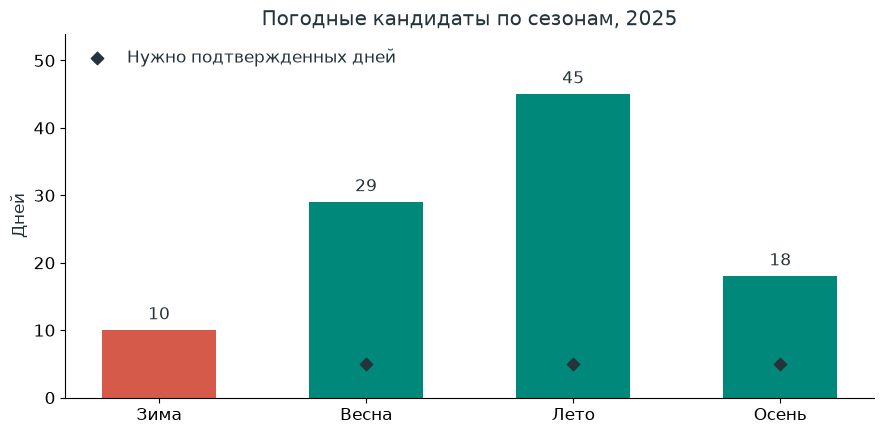

In [2]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'text.color': '#25343B', 'axes.labelcolor': '#25343B'})
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, counts.to_numpy(), color=['#D65A4A', '#00897B', '#00897B', '#00897B'], width=0.55)
ax.scatter(labels[1:], [5, 5, 5], color='#25343B', marker='D', s=40,
           zorder=3, label='Нужно подтвержденных дней')
ax.bar_label(bars, padding=5)
ax.set(title='Погодные кандидаты по сезонам, 2025', ylabel='Дней')
ax.set_ylim(0, counts.max() * 1.2)
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
(base / 'figures').mkdir(exist_ok=True)
fig.savefig(base / 'figures/01_weather_candidates.png', dpi=180, bbox_inches='tight')
plt.show()


Погодные кандидаты проверены по всему дневному интервалу. Для нового сравнения нужны 15 дней трех сезонов. Числа в таблице пока не означают готовую обучающую выборку. Берем дни минимум с 10 пригодными заходами на 09L и 300 учебными парами.

Сравниваем Ridge, Huber, ElasticNet и Polynomial Ridge второй степени с прогнозом по постоянной вертикальной скорости. При изменении числа обучающих дней проверочные дни сохраняем одинаковыми. Выбранные даты и выполненный расчет представлены в ноутбуке 02_seasonal_training.ipynb